EXP 7: WRITE A PYTHON PROGRAM FOR ANALYZING UNIVARIATE DATA (USING HISTOGRAM AND BOXPLOT), BIVARTE DATA (USING SCATTER PLOT, PAIR PLOT, CORRELATION) FROM IRIS DATA SET

In [1]:
#univariate---> it involves single variable 
#bivariate---> it involves two related variable 

In [6]:
#load the data set from the url
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
#sklearn---> Library for machine learning
from sklearn.model_selection import train_test_split

In [34]:
attributes=["sepal_length","sepal_width","petal_length","petal_width","class"]
dataset=pd.read_csv(url,names=attributes)
dataset.columns=attributes
dataset

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [36]:
#types of columns
iris.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

In [29]:
#check the column info
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [30]:
#numercial summary of the data
#numerical summary---> numerical data
iris.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [41]:
#check the no. of instances in each class
iris.groupby('species').size()

species
setosa        50
versicolor    50
virginica     50
dtype: int64

In [39]:
#minimum value
iris.groupby('species').min()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,4.3,2.3,1.0,0.1
versicolor,4.9,2.0,3.0,1.0
virginica,4.9,2.2,4.5,1.4


In [38]:
#maximum value
iris.groupby('species').max()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.8,4.4,1.9,0.6
versicolor,7.0,3.4,5.1,1.8
virginica,7.9,3.8,6.9,2.5


<Axes: >

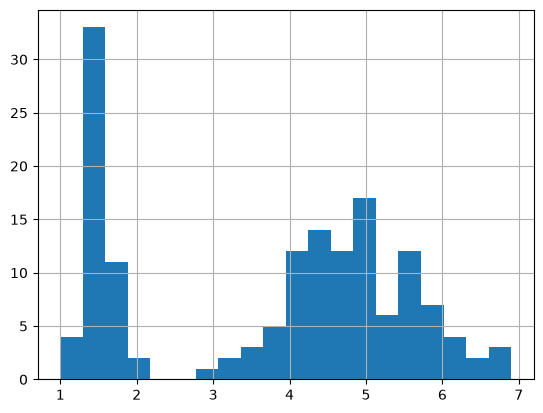

In [46]:
#histogram(univariate data) using pandas 
iris['petal_length'].hist(bins=20)


(array([ 4., 33., 11.,  2.,  0.,  0.,  1.,  2.,  3.,  5., 12., 14., 12.,
        17.,  6., 12.,  7.,  4.,  2.,  3.]),
 array([1.   , 1.295, 1.59 , 1.885, 2.18 , 2.475, 2.77 , 3.065, 3.36 ,
        3.655, 3.95 , 4.245, 4.54 , 4.835, 5.13 , 5.425, 5.72 , 6.015,
        6.31 , 6.605, 6.9  ]),
 <BarContainer object of 20 artists>)

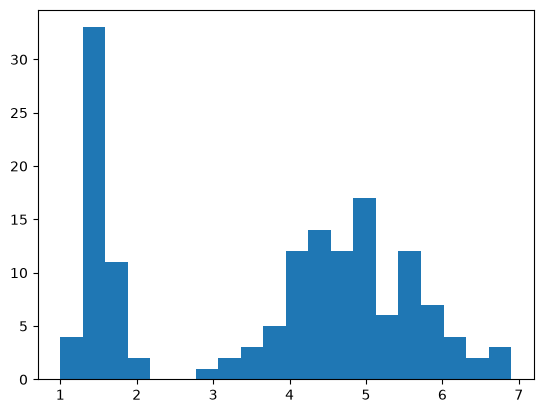

In [45]:
#using matplotlib
plt.hist(data=iris, x='petal_length',bins=20)

<Axes: xlabel='petal_length', ylabel='Count'>

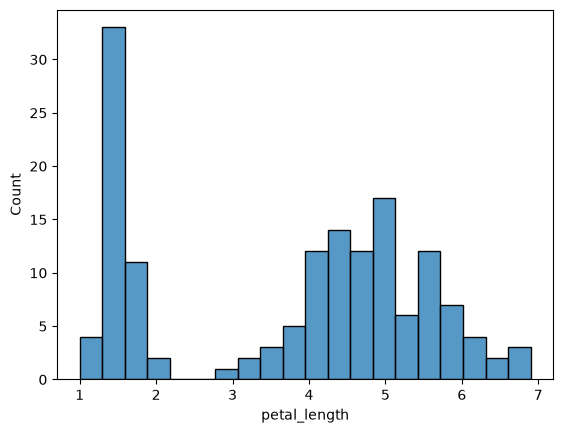

In [47]:
#using seaborn
sns.histplot(iris['petal_length'],bins=20)

array([[<Axes: title={'center': 'sepal_length'}>,
        <Axes: title={'center': 'sepal_width'}>],
       [<Axes: title={'center': 'petal_length'}>,
        <Axes: title={'center': 'petal_width'}>]], dtype=object)

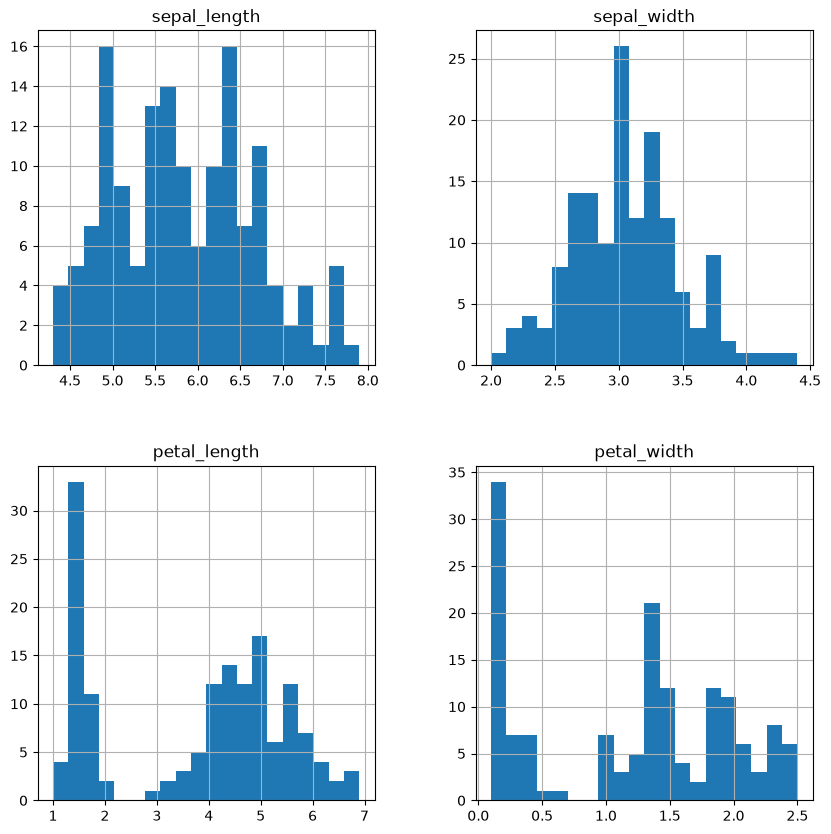

In [48]:
#hsitogram for univariant data of each variable (columns)
iris.hist(bins=20,figsize=(10,10))

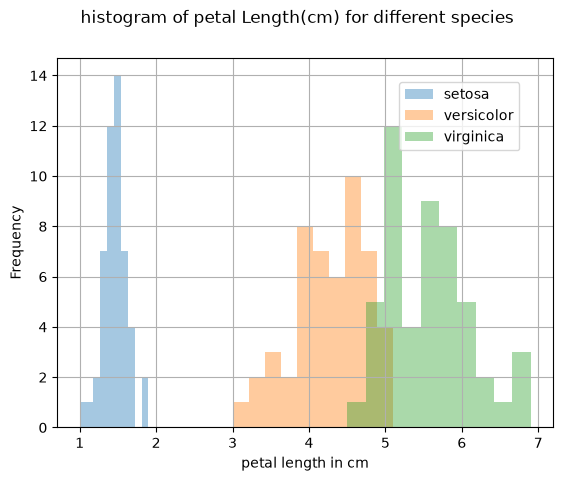

In [51]:
#modify the histogram
#we are selecting species and from that species
#getting the information about the petal length
#iris.groupby('species').petal length
#plotting the histogram
#alpha controls the transperancy
#xlabel--->write something in x axis
#suptitle---> tiele of the diagram
#legend---> to show the different species
#grid--> length
iris.groupby('species').petal_length.plot.hist(alpha=0.4)
plt.xlabel('petal length in cm')
plt.suptitle("histogram of petal Length(cm) for different species")
plt.legend(loc=(0.69,0.75))
plt.grid()

array([5.1, 5.8, 6.4])

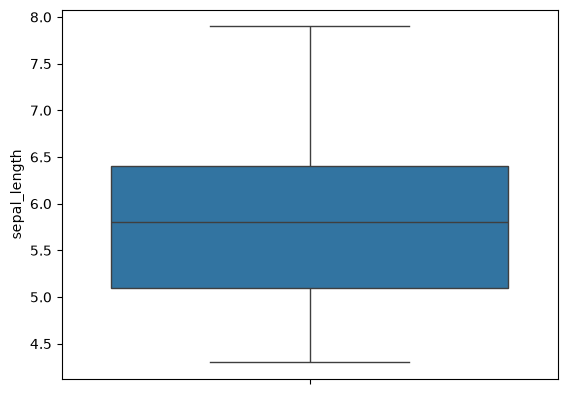

In [54]:
#box plot
sns.boxplot(data=iris,y='sepal_length')
min(iris['sepal_length'])
max(iris['sepal_length'])
np.median(iris['sepal_length'])
iris.sepal_length.quantile([0.25,0.5,0.75])
np.percentile(iris.sepal_length,[25,50,75])

<Axes: xlabel='species', ylabel='sepal_length'>

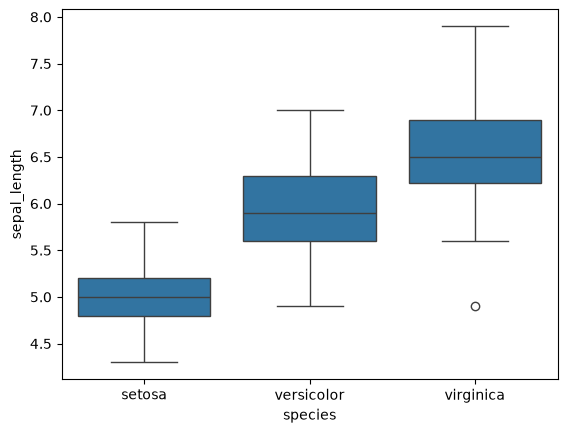

In [55]:
#box plot for each categories
sns.boxplot(data=iris,x='species',y='sepal_length')


<Axes: xlabel='species', ylabel='sepal_length'>

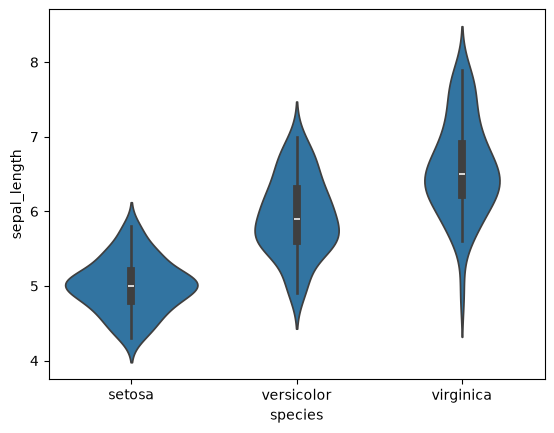

In [56]:
sns.violinplot(data=iris,x='species',y='sepal_length')

<Axes: xlabel='petal_length', ylabel='petal_width'>

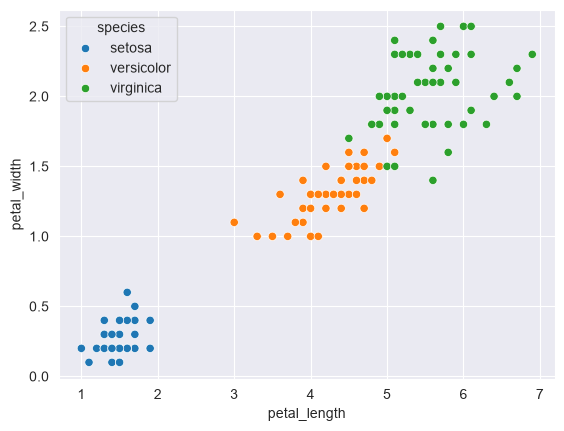

In [57]:
# bivariate data--->two or more variables
#scatter plot
sns.set_style('darkgrid')
#based on species what is the petal length and petal width
sns.scatterplot(data=iris,x='petal_length',y='petal_width',hue='species')


<Axes: xlabel='petal_length', ylabel='sepal_length'>

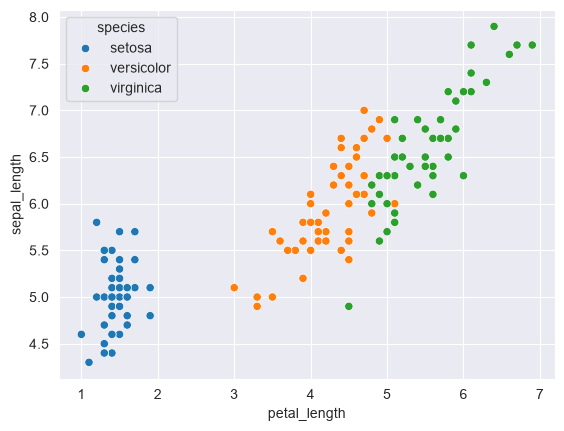

In [58]:
sns.scatterplot(data=iris,x='petal_length',y='sepal_length',hue='species')

species
setosa        Axes(0.125,0.11;0.775x0.77)
versicolor    Axes(0.125,0.11;0.775x0.77)
virginica     Axes(0.125,0.11;0.775x0.77)
dtype: object

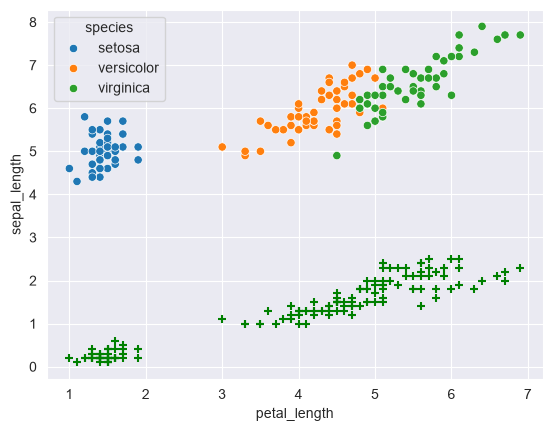

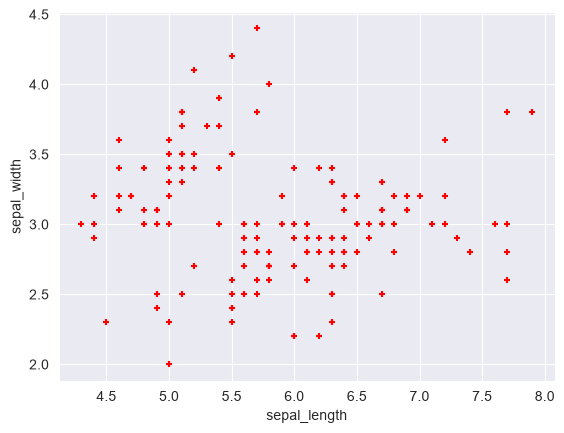

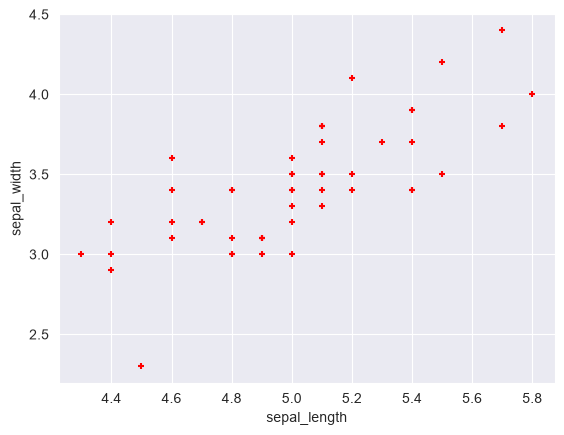

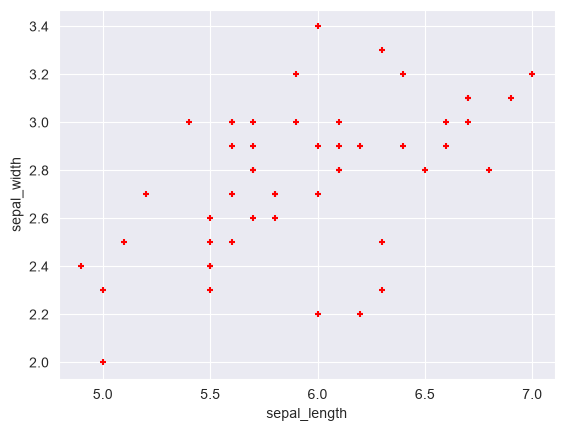

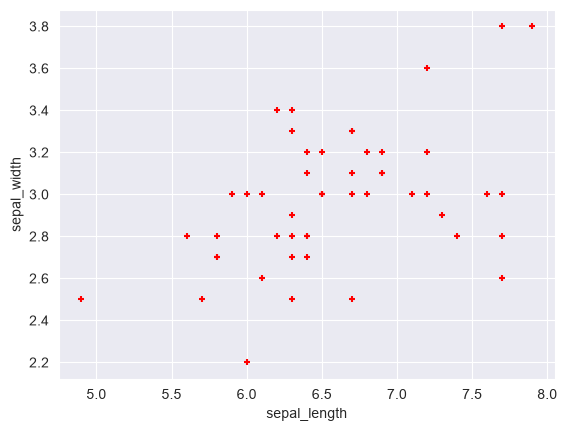

In [59]:
#seaborn
sns.scatterplot(data=iris,x='petal_length',y='sepal_length',hue='species')
#matplotlib
plt.scatter(data=iris,x='petal_length',y='petal_width',c='green',marker="+")
#pandas
iris.plot.scatter(x='sepal_length',y='sepal_width',c='red',marker='+',s=15)
iris.groupby('species').plot.scatter(x='sepal_length',y='sepal_width',c='red',marker='+',s=15)

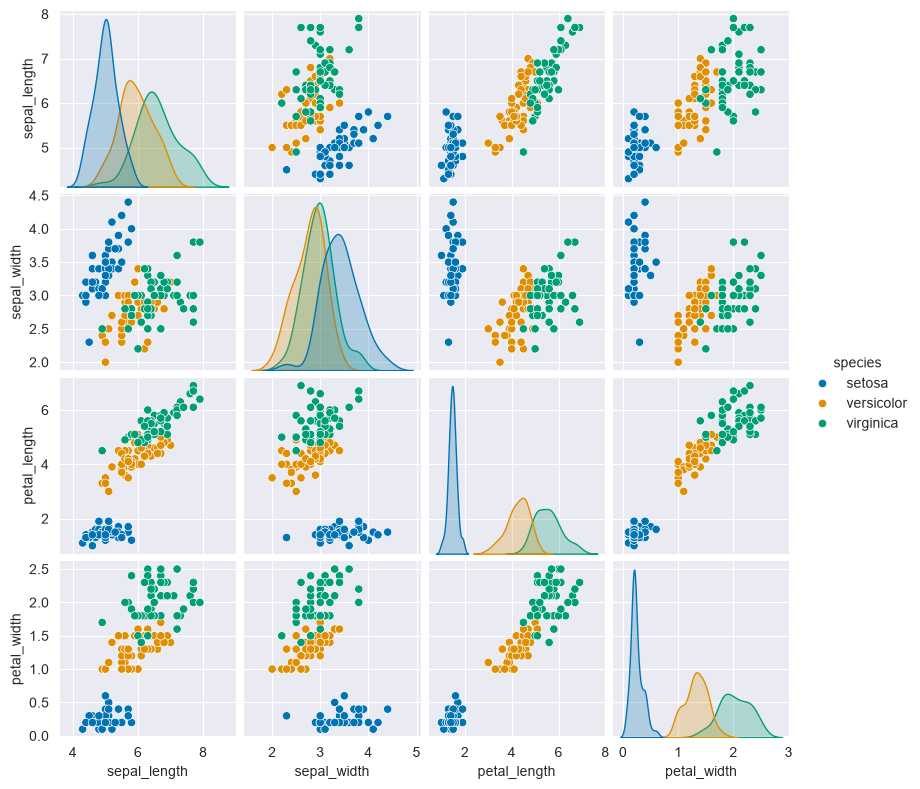

In [61]:
#pair plot
#check the relationship between 2 variables group them by species
sns.pairplot(iris,hue='species',height=2,palette='colorblind')

Text(0.5, 0.98, 'Heatmap')

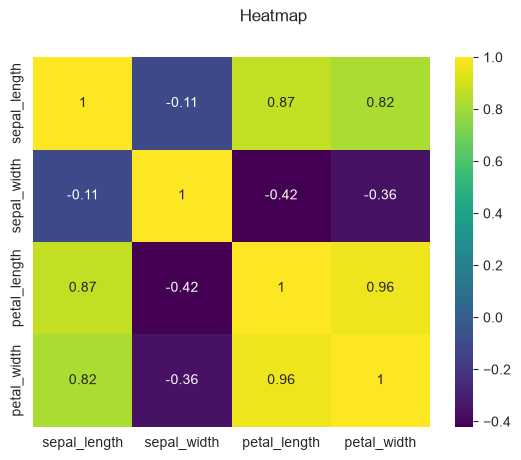

In [62]:
#heat map
sns.heatmap(iris.drop('species',axis=1).corr(),cmap='viridis',annot=True)
plt.suptitle('Heatmap')